In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1.2)
font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])

Current font settings: ['Helvetica']


## Download evaluation results

In [1]:
import random

random.seed(42)
seeds = random.sample(range(1,2024),5)
seeds

[1310, 229, 52, 1519, 564]

In [2]:
cell_lines = ['CPJUMP1_A549', 'CPJUMP1_U2OS']

In [ ]:
import pandas as pd 
import wandb

api = wandb.Api()

for j, cell_line in enumerate(cell_lines):
    runs = api.runs(f"lynnymli/{cell_line}")

    models = ["pretrain-no-perturb", "pretrain-no-pretrain", "pretrain-finetune", "ground-truth"]
    metrics = ['test_mse', 'test_pearson']
    train_fracs = [0.2, 0.4, 0.6, 0.8]

    result_df=pd.DataFrame()
    i = 0
    for run in runs: 
        if run.summary._json_dict == {}: continue
        for seed in seeds:
            filtered_dict = {key: run.summary._json_dict[key] for key in run.summary._json_dict if key in metrics+['_runtime']}
            if i == 0:
                result_df = pd.DataFrame(filtered_dict, index=[i]).T
                result_df.columns = [run.name+f'_{cell_line}']
                # print(result_df)
            else:
                result_df[run.name+f'_{cell_line}'] = pd.DataFrame(filtered_dict, index=[i]).T.values
            i += 1

    result_df = result_df.T
    result_df = result_df[metrics]

    assert result_df.shape[0] == len(models) * len(seeds) * len(train_fracs)

    result_df['model'] = result_df.index.map(lambda idx: idx.split('_')[0] if '_' in idx else idx)
    result_df['seed'] = result_df.index.map(lambda idx: int(idx.split('_')[1]) if '_' in idx else idx)
    result_df['train_frac'] = result_df.index.map(lambda idx: idx.split('_')[2] if '_' in idx else idx)
    result_df['cell_line'] = cell_line
    
    if j == 0:
        all_res =  result_df
    else:
        all_res = pd.concat([all_res, result_df], axis=0)

len(all_res)


160

In [10]:
all_res = all_res.drop(columns=['seed'])
overall_results = all_res.groupby(['model']).mean(numeric_only = True)
metric_rank = pd.DataFrame(index=models)
for metric in metrics:
    if 'pearson' in metric:
        metric_rank[metric] = overall_results[metric].rank(ascending=False, method='min')
    else:
        metric_rank[metric] = overall_results[metric].rank(ascending=True, method='min')
metric_rank = metric_rank.astype(int)
metric_rank

,test_mse,test_pearson
pretrain-no-perturb,3,4
pretrain-no-pretrain,4,3
pretrain-finetune,2,2
ground-truth,1,1


In [11]:
all_res.groupby(['cell_line', 'train_frac', 'model']).mean(numeric_only = True)

test_mse  test_pearson
cell_line    train_frac model                                        
CPJUMP1_A549 0.2        ground-truth           1.472740      0.751178
                        pretrain-finetune     11.286523      0.040398
                        pretrain-no-perturb   11.372981      0.010229
                        pretrain-no-pretrain  11.314356      0.012012
             0.4        ground-truth           1.527476      0.749206
                        pretrain-finetune     10.779305      0.033649
                        pretrain-no-perturb   10.816145      0.010978
                        pretrain-no-pretrain  10.865636      0.024387
             0.6        ground-truth           1.614836      0.743807
                        pretrain-finetune     10.290370      0.052026
                        pretrain-no-perturb   10.346194      0.014221
                        pretrain-no-pretrain  10.312738      0.049939
             0.8        ground-truth           1.275588      0.745422
                        pretrain-finetune      9.281709      0.037414
                        pretrain-no-perturb    9.379506      0.002419
                        pretrain-no-pretrain   9.175793      0.050220
CPJUMP1_U2OS 0.2        ground-truth           6.159219      0.574178
                        pretrain-finetune     19.365837      0.059427
                        pretrain-no-perturb   19.398654      0.050246
                        pretrain-no-pretrain  19.286742      0.048031
             0.4        ground-truth           6.300558      0.572399
                        pretrain-finetune     18.113618      0.069636
                        pretrain-no-perturb   18.129962      0.055576
                        pretrain-no-pretrain  18.363034      0.045847
             0.6        ground-truth           6.541501      0.566503
                        pretrain-finetune     17.870827      0.073810
                        pretrain-no-perturb   17.886703      0.058505
                        pretrain-no-pretrain  17.782398      0.074173
             0.8        ground-truth           6.355646      0.559107
                        pretrain-finetune     17.973767      0.088405
                        pretrain-no-perturb   18.587255      0.062267
                        pretrain-no-pretrain  18.905730      0.085675

In [ ]:
def normalize_results(df, metrics):
    new_df = df.copy()
    for i, row in new_df.iterrows():
        model = row['model']
        for m in metrics:
            if 'mse' in m:
                new_df.loc[i, m] = (new_df.loc[i, m]) - (df.loc[i.replace(model, 'pretrain-no-perturb'), m]) + 1
            elif 'pearson' in m:
                new_df.loc[i, m] = (new_df.loc[i, m]) - (df.loc[i.replace(model, 'pretrain-no-perturb'), m])
            else:
                continue
    return new_df

In [13]:
norm_df = normalize_results(all_res, ['test_mse', 'test_pearson'])
norm_df

,test_mse,test_pearson,model,train_frac,cell_line
ground-truth_229_0.6_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_A549,-6.463030,0.680054,ground-truth,0.6,CPJUMP1_A549
ground-truth_52_0.2_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_A549,-9.065117,0.748907,ground-truth,0.2,CPJUMP1_A549
ground-truth_564_0.4_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_A549,-9.607227,0.760513,ground-truth,0.4,CPJUMP1_A549
ground-truth_1519_0.6_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_A549,-6.326241,0.737706,ground-truth,0.6,CPJUMP1_A549
ground-truth_564_0.6_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_A549,-10.182951,0.721753,ground-truth,0.6,CPJUMP1_A549
...,...,...,...,...,...
pretrain-finetune_1310_0.4_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_U2OS,1.182056,-0.004697,pretrain-finetune,0.4,CPJUMP1_U2OS
pretrain-no-pretrain_52_0.2_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_U2OS,0.846182,-0.008614,pretrain-no-pretrain,0.2,CPJUMP1_U2OS
pretrain-no-pretrain_1519_0.6_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_U2OS,0.941513,-0.007263,pretrain-no-pretrain,0.6,CPJUMP1_U2OS
pretrain-no-pretrain_1519_0.8_cross_perturb_5splits_CPJUMP1_normalized_feature_select_batch_ctrl3_CPJUMP1_U2OS,0.497583,0.035396,pretrain-no-pretrain,0.8,CPJUMP1_U2OS


In [14]:
# norm_df = norm_df.drop(columns=['seed'])
overall_results = norm_df.groupby(['model']).mean(numeric_only = True)
metric_rank = pd.DataFrame(index=models)
for metric in metrics:
    if 'pearson' in metric:
        metric_rank[metric] = overall_results[metric].rank(ascending=False, method='min')
    else:
        metric_rank[metric] = overall_results[metric].rank(ascending=True, method='min')
metric_rank = metric_rank.astype(int)
metric_rank

,test_mse,test_pearson
pretrain-no-perturb,3,4
pretrain-no-pretrain,4,3
pretrain-finetune,2,2
ground-truth,1,1


In [ ]:
import seaborn as sns

models = ["pretrain-no-perturb", "pretrain-no-pretrain", "pretrain-finetune"]
custom_palette = sns.color_palette(['darkgray', '#297abd', '#ce403d'], n_colors=4)

norm_df = norm_df[norm_df['model'].isin(models)].loc[:, metrics+['model', 'train_frac', 'cell_line']]
norm_df['rank'] = norm_df['model'].apply(lambda x: models.index(x))
norm_df = norm_df.sort_values(by=['rank', 'train_frac'], ascending=True)
# norm_df


Current font settings: ['Helvetica']


/tmp/ipykernel_623293/769008766.py:27: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(
/tmp/ipykernel_623293/769008766.py:27: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(


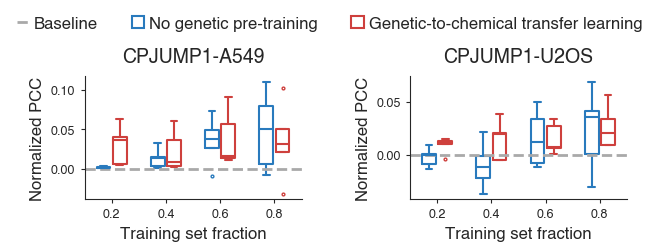

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=len(cell_lines), figsize=(7, 1.6))
if not isinstance(axes, np.ndarray):
    axes = [axes]

for ax, cell_line in zip(axes, cell_lines):
    subset_res = norm_df[norm_df['cell_line'] == cell_line]
    subset_res = subset_res[subset_res['model'] != 'pretrain-no-perturb']
    
    sns.boxplot(
        data=subset_res,
        x="train_frac", 
        y="test_pearson", 
        hue="model", 
        palette=custom_palette[1:],
        width=0.6,
        fliersize=2,
        linewidth=1.5,
        fill=False,
        gap=.15,
        ax=ax
    )
    title = cell_line.replace('_', '-')
    ax.set_title(f'{title}', fontsize=14, pad=10)
    ax.set_xlabel('Training set fraction', fontsize=12)
    if 'A549' in cell_line:
        ax.set_ylabel('Normalized PCC', fontsize=12)
    else:
        ax.set_ylabel('Normalized PCC', fontsize=12)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_linewidth(0.8)
    ax.spines['left'].set_linewidth(0.8)
    ax.tick_params(axis='both', which='major', labelsize=9, width=0.8, length=3)
    ax.axhline(y=0, color=custom_palette[0], linestyle='--', linewidth=2)
    ax.get_legend().remove()

# Create a unified legend
handles, labels = ax.get_legend_handles_labels()

# Add the gray dashed line to the legend
gray_line = Line2D([0], [0], color=custom_palette[0], linestyle='--', linewidth=2)
handles.append(gray_line)
labels.append('Baseline')

# Reorder the handles and labels to put the baseline first
handles = [handles[-1]] + handles[:-1]
labels = ['Baseline', 'No genetic pre-training', 'Genetic-to-chemical transfer learning']

fig.legend(handles, labels, 
           loc='upper center', 
           bbox_to_anchor=(0.475, 1.35), 
           ncol=3, 
           fontsize=12,
           facecolor='white', 
           framealpha=1.0, 
           handletextpad=0.3,
           handlelength=0.75,
           edgecolor='white'
           )

plt.subplots_adjust(wspace=0.5)
plt.show()

Current font settings: ['Helvetica']


/tmp/ipykernel_623293/2248071735.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(
/tmp/ipykernel_623293/2248071735.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(


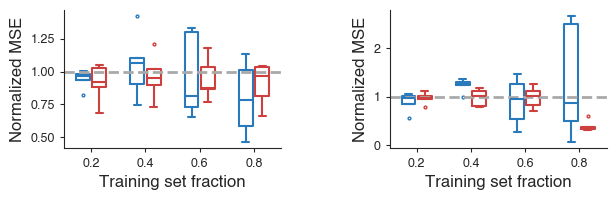

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=len(cell_lines), figsize=(7, 1.8))
if not isinstance(axes, np.ndarray):
    axes = [axes]

for ax, cell_line in zip(axes, cell_lines):
    subset_res = norm_df[norm_df['cell_line'] == cell_line]
    subset_res = subset_res[subset_res['model'] != 'pretrain-no-perturb']
    
    sns.boxplot(
        data=subset_res,
        x="train_frac", 
        y="test_mse", 
        hue="model", 
        palette=custom_palette[1:],
        width=0.6,
        fliersize=2,
        linewidth=1.5,
        fill=False,
        gap=.15,
        ax=ax
    )
    
    ax.set_xlabel('Training set fraction', fontsize=12)
    if 'A549' in cell_line:
        ax.set_ylabel('Normalized MSE', fontsize=12)
    else:
        ax.set_ylabel('Normalized MSE', fontsize=12)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_linewidth(0.8)
    ax.spines['left'].set_linewidth(0.8)
    ax.tick_params(axis='both', which='major', labelsize=9, width=0.8, length=3)
    ax.axhline(y=1, color=custom_palette[0], linestyle='--', linewidth=2)
    ax.get_legend().remove()

plt.subplots_adjust(wspace=0.5)
plt.show()